In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [6]:
df = pd.read_csv("cifar-10.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (50000, 3073)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [7]:
X = df.drop("label", axis=1).values
y = df["label"].values

print("Features Shape:", X.shape)
print("Labels Shape:", y.shape)

Features Shape: (50000, 3072)
Labels Shape: (50000,)


In [8]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

In [9]:
X = X.astype('float32') / 255.0

print("Normalized Shape:", X.shape)

Normalized Shape: (50000, 3072)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (40000, 3072)
Testing: (10000, 3072)


In [11]:
model = Sequential([
    Input(shape=(3072,)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

E0000 00:00:1794652153.542157   83128 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.2931 - loss: 1.9614 - val_accuracy: 0.3636 - val_loss: 1.7801
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.3749 - loss: 1.7379 - val_accuracy: 0.3831 - val_loss: 1.7174
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.4053 - loss: 1.6573 - val_accuracy: 0.3895 - val_loss: 1.6911
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.4311 - loss: 1.5925 - val_accuracy: 0.4270 - val_loss: 1.6048
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.4497 - loss: 1.5427 - val_accuracy: 0.4252 - val_loss: 1.6054
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.4595 - loss: 1.5078 - val_accuracy: 0.4608 - val_loss: 1.5224
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.4732 - loss: 1.4814 - val_accuracy: 0.4761 - val_loss: 1.4875
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.4807 - loss: 1.4478 - val_accu

In [13]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Loss:", loss)
print("Testing Accuracy:", accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4740 - loss: 1.4973
Testing Loss: 1.497300148010254
Testing Accuracy: 47.40000069141388 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


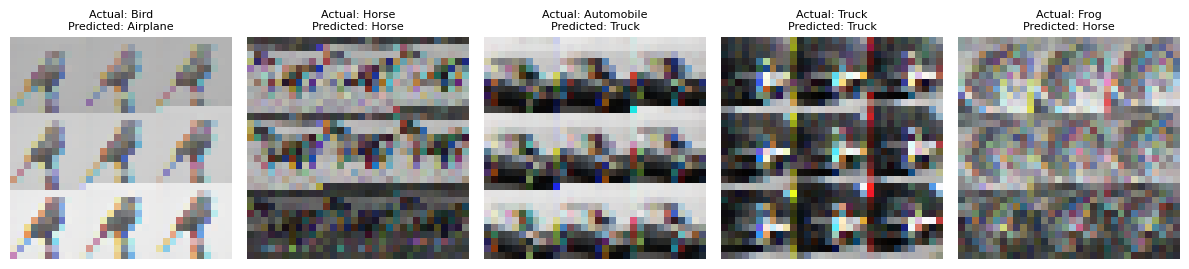

In [14]:
predictions = model.predict(X_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    image = X_test[i].reshape(32, 32, 3)

    plt.imshow(image)
    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted_labels[i]]}",
        fontsize=8
    )
    plt.axis('off')

plt.tight_layout()
plt.show()